# Assignment 7

Sharpening with the Laplacian, Sobel, Canny and unsharp masking.

Sample: `sample_portrait.jpg` (hair, eyes, collar). The unsharp mask uses a 5x5 Gaussian with sigma 3.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# sharpening
# laplacian, sobel gradient, canny, and unsharp masking
# unsharp blur is gaussian 5x5 with sigma = 3, as asked

def laplacian_sharpen(img):
    # centre is negative, so sharpened = f - laplacian(f)
    kernel = np.array([[0, 1, 0],
                       [1, -4, 1],
                       [0, 1, 0]], dtype=np.float64)
    lap = cv2.filter2D(img.astype(np.float64), cv2.CV_64F, kernel)
    sharp = np.clip(img.astype(np.float64) - lap, 0, 255)
    return lap, sharp.astype(np.uint8)


def sobel_gradient(img):
    kx = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]], dtype=np.float64)
    ky = np.array([[-1, -2, -1],
                   [0, 0, 0],
                   [1, 2, 1]], dtype=np.float64)
    src = img.astype(np.float64)
    gx = cv2.filter2D(src, cv2.CV_64F, kx)
    gy = cv2.filter2D(src, cv2.CV_64F, ky)
    mag = np.hypot(gx, gy)
    if mag.max() == 0:
        return np.zeros_like(img)
    show = np.clip(np.round(mag / mag.max() * 255), 0, 255)
    return show.astype(np.uint8)


def non_max_suppression(mag, angle):
    # angle is in degrees, 0 to 180. keep a pixel only if it is
    # bigger than the two neighbours that lie along the gradient
    m = np.pad(mag, 1, mode="constant")
    c = m[1:-1, 1:-1]
    n = m[0:-2, 1:-1]
    s = m[2:, 1:-1]
    w = m[1:-1, 0:-2]
    e = m[1:-1, 2:]
    ne = m[0:-2, 2:]
    nw = m[0:-2, 0:-2]
    se = m[2:, 2:]
    sw = m[2:, 0:-2]

    d0 = (angle < 22.5) | (angle >= 157.5)
    d45 = (angle >= 22.5) & (angle < 67.5)
    d90 = (angle >= 67.5) & (angle < 112.5)
    d135 = (angle >= 112.5) & (angle < 157.5)

    keep = np.zeros(mag.shape, dtype=bool)
    keep[d0] = (c[d0] >= e[d0]) & (c[d0] >= w[d0])
    keep[d45] = (c[d45] >= ne[d45]) & (c[d45] >= sw[d45])
    keep[d90] = (c[d90] >= n[d90]) & (c[d90] >= s[d90])
    keep[d135] = (c[d135] >= nw[d135]) & (c[d135] >= se[d135])

    out = np.zeros_like(mag)
    out[keep] = mag[keep]
    return out


def hysteresis(mag, low, high):
    strong = mag >= high
    weak = (mag >= low) & ~strong
    out = strong.copy()
    # grow the strong edges into weak pixels that touch them
    while True:
        dil = out.copy()
        dil[1:, :] |= out[:-1, :]
        dil[:-1, :] |= out[1:, :]
        dil[:, 1:] |= out[:, :-1]
        dil[:, :-1] |= out[:, 1:]
        dil[1:, 1:] |= out[:-1, :-1]
        dil[:-1, :-1] |= out[1:, 1:]
        dil[1:, :-1] |= out[:-1, 1:]
        dil[:-1, 1:] |= out[1:, :-1]
        grow = dil & weak
        if not np.any(grow):
            break
        out[grow] = True
        weak[grow] = False
    edge = np.zeros(mag.shape, dtype=np.uint8)
    edge[out] = 255
    return edge


def canny_edges(img, sigma=1.4):
    blur = cv2.GaussianBlur(img.astype(np.float64), (5, 5), sigma)
    kx = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]], dtype=np.float64)
    ky = np.array([[-1, -2, -1],
                   [0, 0, 0],
                   [1, 2, 1]], dtype=np.float64)
    gx = cv2.filter2D(blur, cv2.CV_64F, kx)
    gy = cv2.filter2D(blur, cv2.CV_64F, ky)
    mag = np.hypot(gx, gy)
    # drop floating-point dust, otherwise flat areas look like edges
    mag[mag < 1e-3] = 0
    angle = np.degrees(np.arctan2(gy, gx)) % 180
    thin = non_max_suppression(mag, angle)

    nz = thin[thin >= 1.0]
    if nz.size == 0:
        return np.zeros(img.shape, dtype=np.uint8), 0.0, 0.0
    # upper cut sits above most of the weak gradient so texture stays quiet
    high = float(np.percentile(nz, 75))
    low = high * 0.4
    return hysteresis(thin, low, high), low, high


def unsharp_mask(img):
    # question: gaussian 5x5, sigma = 3
    blur = cv2.GaussianBlur(img, (5, 5), 3)
    mask = img.astype(np.float64) - blur.astype(np.float64)
    k = 1
    sharp = img.astype(np.float64) + k * mask
    return np.clip(np.round(sharp), 0, 255).astype(np.uint8)


sample image: sample_portrait.jpg (256, 256)
canny low = 27.0  high = 67.49
unsharp masking uses gaussian 5x5, sigma 3, k = 1


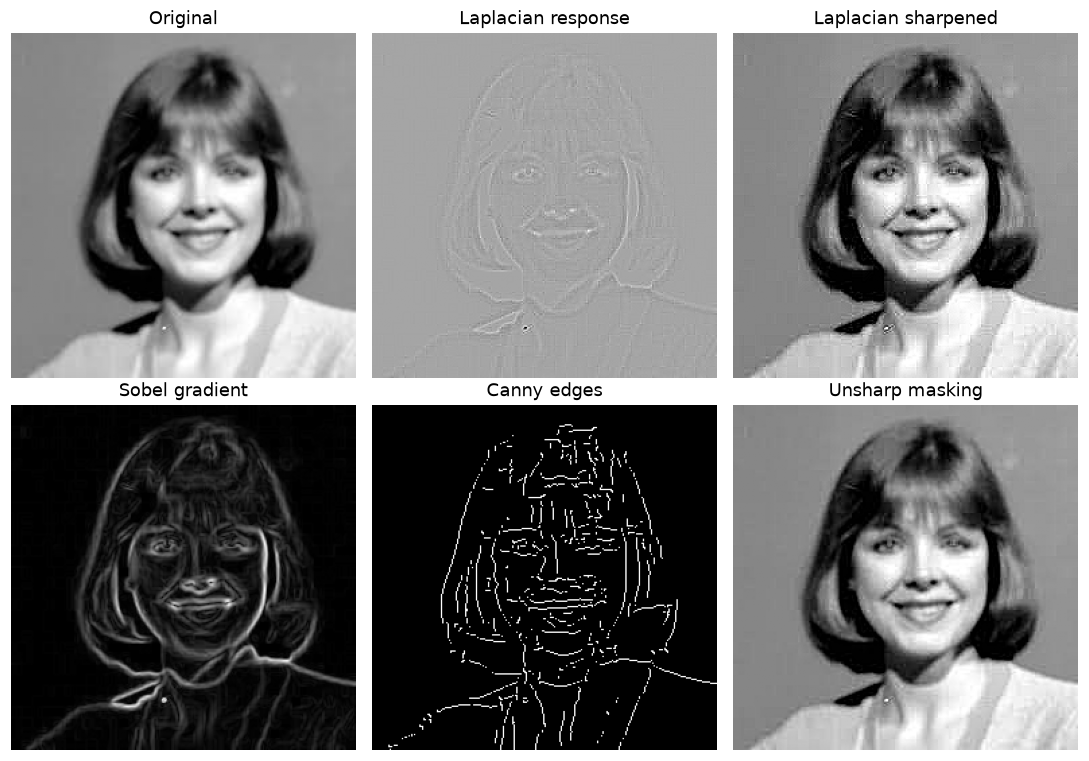

In [2]:
image_path = "sample_portrait.jpg"
img = cv2.imread(image_path, 0)
print("sample image:", image_path, img.shape)

lap, lap_sharp = laplacian_sharpen(img)
sobel = sobel_gradient(img)
canny, low, high = canny_edges(img)
unsharp = unsharp_mask(img)
print("canny low =", round(low, 2), " high =", round(high, 2))
print("unsharp masking uses gaussian 5x5, sigma 3, k = 1")

plt.figure(figsize=(10, 7))
plt.subplot(2, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(lap, cmap="gray")
plt.title("Laplacian response")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(lap_sharp, cmap="gray", vmin=0, vmax=255)
plt.title("Laplacian sharpened")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(sobel, cmap="gray", vmin=0, vmax=255)
plt.title("Sobel gradient")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(canny, cmap="gray", vmin=0, vmax=255)
plt.title("Canny edges")
plt.axis("off")
plt.subplot(2, 3, 6)
plt.imshow(unsharp, cmap="gray", vmin=0, vmax=255)
plt.title("Unsharp masking")
plt.axis("off")
plt.tight_layout()
plt.show()
